In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
df = pd.read_csv("../data/ai4i2020.csv")

df = df.rename(columns={
    "UDI": "udi",
    "Product ID": "product_id",
    "Type": "type",
    "Air temperature [K]": "air_temperature",
    "Process temperature [K]": "process_temperature",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure"
})

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 14)


,udi,product_id,type,air_temperature,process_temperature,rotational_speed,torque,tool_wear,machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df["temperature_difference"] = (
    df["process_temperature"] - df["air_temperature"]
)

df["mechanical_power"] = (
    df["torque"] * df["rotational_speed"] * (2 * np.pi / 60)
)

df["wear_torque_interaction"] = (
    df["tool_wear"] * df["torque"]
)

features = [
    "type",
    "air_temperature",
    "process_temperature",
    "rotational_speed",
    "torque",
    "tool_wear",
    "temperature_difference",
    "mechanical_power",
    "wear_torque_interaction"
]

target = "machine_failure"

X = df[features]
y = df[target]

print("Features:", features)
print("\nTarget distribution:")
print(y.value_counts())

Features: ['type', 'air_temperature', 'process_temperature', 'rotational_speed', 'torque', 'tool_wear', 'temperature_difference', 'mechanical_power', 'wear_torque_interaction']

Target distribution:
machine_failure
0    9661
1     339
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [5]:
categorical_features = ["type"]

numerical_features = [
    col for col in features
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 11)
Processed testing shape: (2000, 11)


In [6]:
random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(
    X_train_processed,
    y_train
)

print("Random Forest training completed.")

Random Forest training completed.


In [7]:
rf_predictions = random_forest.predict(X_test_processed)

rf_probabilities = random_forest.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions generated.")

print("\nFirst 10 failure probabilities:")
print(rf_probabilities[:10])

Predictions generated.

First 10 failure probabilities:
[0.15730133 0.         0.1788941  0.00655667 0.02912571 0.01234757
 0.02887887 0.00968375 0.         0.02569468]


In [8]:
rf_metrics = {
    "Accuracy": accuracy_score(y_test, rf_predictions),
    "Precision": precision_score(
        y_test, rf_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, rf_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, rf_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, rf_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_test, rf_probabilities
    )
}

rf_results = pd.DataFrame(
    [rf_metrics],
    index=["Random Forest"]
)

display(rf_results.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Random Forest,0.9915,0.9474,0.7941,0.864,0.9822,0.8811


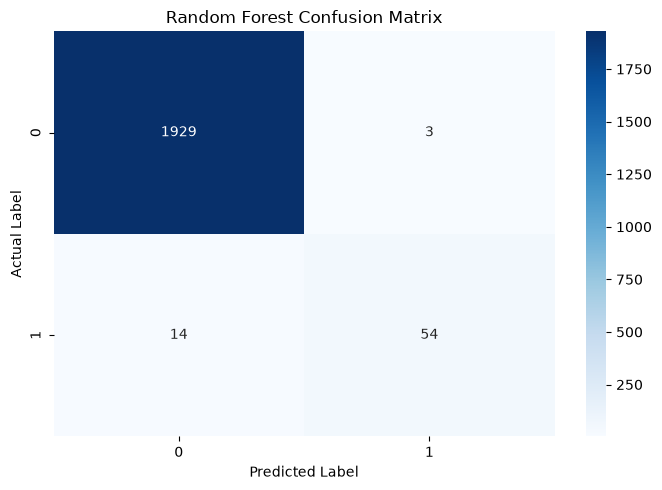

In [9]:
cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

,Feature,Importance
2,num__rotational_speed,0.217370
3,num__torque,0.180361
6,num__mechanical_power,0.179088
4,num__tool_wear,0.140870
7,num__wear_torque_interaction,0.115017
5,num__temperature_difference,0.082719
0,num__air_temperature,0.047228
1,num__process_temperature,0.027074
10,cat__type_M,0.004133
9,cat__type_L,0.004100


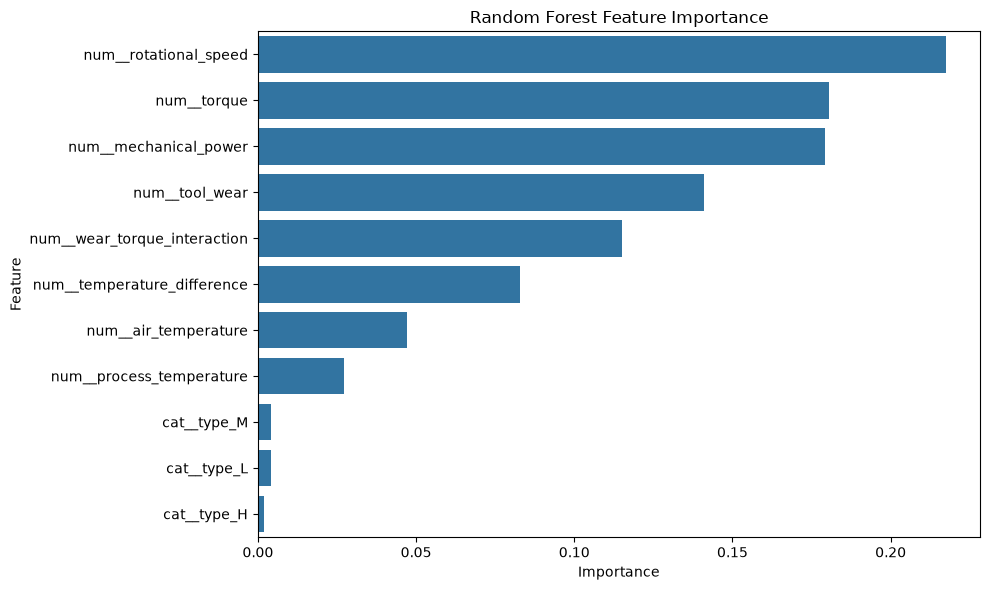

In [10]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": random_forest.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

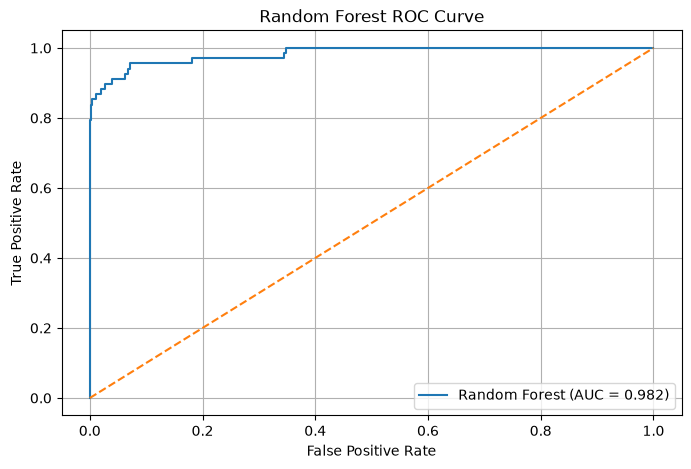

In [11]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    rf_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {rf_metrics['ROC-AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend()
plt.grid()

plt.show()

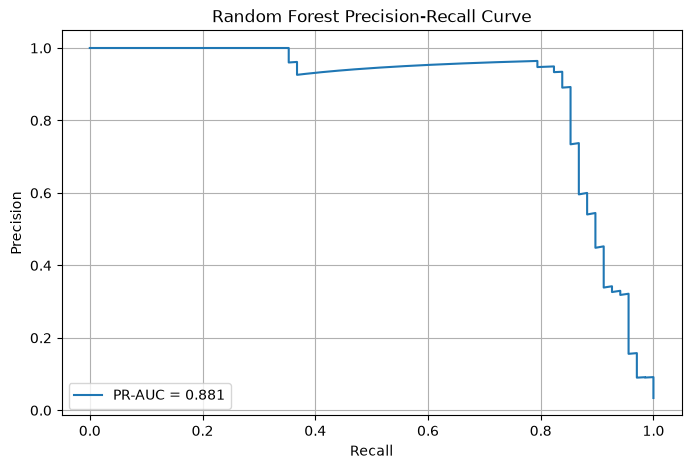

In [12]:
precision_values, recall_values, thresholds = precision_recall_curve(
    y_test,
    rf_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall_values,
    precision_values,
    label=f"PR-AUC = {rf_metrics['PR-AUC']:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest Precision-Recall Curve")
plt.legend()
plt.grid()

plt.show()

In [13]:
logistic_path = "../models/logistic_regression_pipeline.joblib"

logistic_pipeline = joblib.load(logistic_path)

print("Logistic Regression pipeline loaded.")

Logistic Regression pipeline loaded.


In [14]:
logistic_predictions = logistic_pipeline.predict(X_test)

logistic_probabilities = logistic_pipeline.predict_proba(
    X_test
)[:, 1]

logistic_metrics = {
    "Accuracy": accuracy_score(y_test, logistic_predictions),
    "Precision": precision_score(
        y_test, logistic_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, logistic_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, logistic_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, logistic_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_test, logistic_probabilities
    )
}

comparison = pd.DataFrame(
    [logistic_metrics, rf_metrics],
    index=["Logistic Regression", "Random Forest"]
)

display(comparison.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.8585,0.1791,0.8824,0.2978,0.9385,0.4297
Random Forest,0.9915,0.9474,0.7941,0.8640,0.9822,0.8811


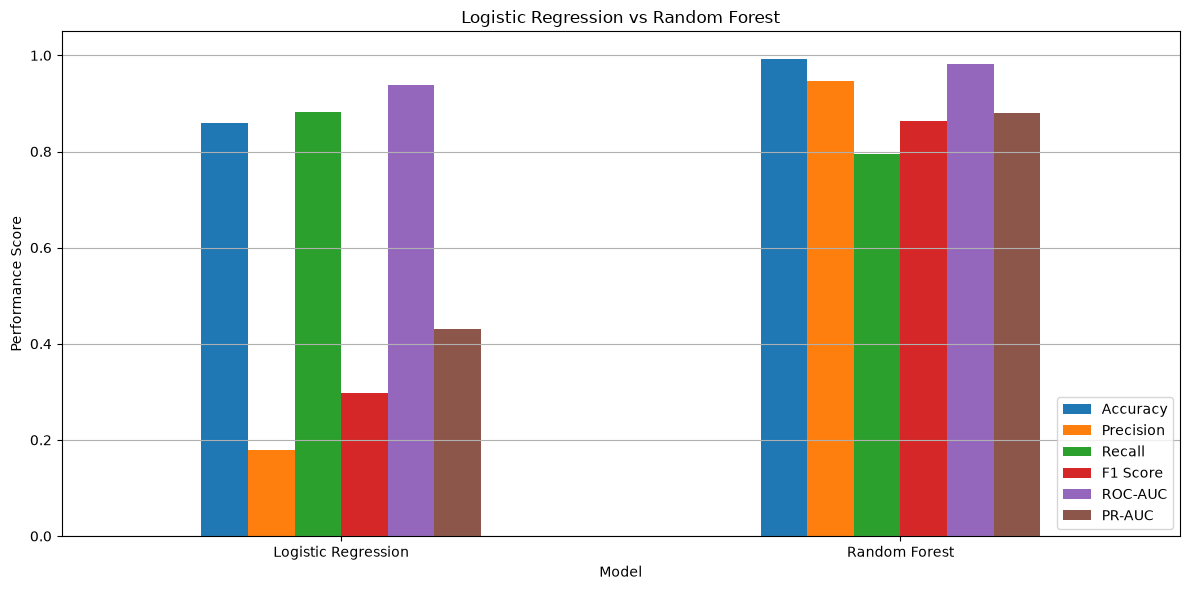

In [15]:
comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Performance Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [16]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)
os.makedirs("../results/predictions", exist_ok=True)

rf_pipeline = {
    "preprocessor": preprocessor,
    "model": random_forest,
    "features": features,
    "target": target
}

joblib.dump(
    rf_pipeline,
    "../models/random_forest_pipeline.joblib"
)

print("Random Forest pipeline saved successfully.")

Random Forest pipeline saved successfully.


In [17]:
comparison.to_csv(
    "../results/metrics/model_comparison_logistic_vs_rf.csv"
)

importance_df.to_csv(
    "../results/metrics/random_forest_feature_importance.csv",
    index=False
)

rf_predictions_df = pd.DataFrame({
    "actual_failure": y_test.values,
    "predicted_failure": rf_predictions,
    "failure_probability": rf_probabilities
})

rf_predictions_df.to_csv(
    "../results/predictions/random_forest_predictions.csv",
    index=False
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.
